# BT4012 Kaggle — baseline + temporal validation
Goal: set up a validation scheme that mimics the real split (train on the past, predict the future), compare a few simple models, and make a first submission.

In [1]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
import warnings
warnings.filterwarnings('ignore')

SEED = 42

## Load

In [2]:
feats = [f'feat_{i}' for i in range(1, 166)]
local = feats[:93]   # assumed local feats (original Elliptic layout)
dtypes = {f: 'float32' for f in feats}

train = pd.read_csv('../data/train.csv', dtype=dtypes)
test = pd.read_csv('../data/test.csv', dtype=dtypes)
edges = pd.read_csv('../data/txs_edgelist.csv')

# degree from the full edgelist (includes the hidden nodes, so it's computed the same way for train and test)
indeg = edges.txId2.value_counts()
outdeg = edges.txId1.value_counts()
for df in (train, test):
    df['in_deg'] = df.txId.map(indeg).fillna(0)
    df['out_deg'] = df.txId.map(outdeg).fillna(0)

# only labelled rows are used for supervised training
lab = train[train.label.notna()].copy()
lab['y'] = lab.label.astype(int)
lab.shape

(31235, 171)

## Temporal validation split
Test = steps 36–49 (future). So validate the same way: fit on steps 1–25, validate on 26–35.
No random k-fold since txs in the same step are connected -> leakage + over-optimistic scores.

In [3]:
fit = lab[lab.time_step <= 25]
val = lab[lab.time_step > 25]
print(f'fit: {len(fit)} rows, illicit {fit.y.mean():.3f}')
print(f'val: {len(val)} rows, illicit {val.y.mean():.3f}')

fit: 24200 rows, illicit 0.097
val: 7035 rows, illicit 0.186


In [4]:
results = {}
per_step = {}

def evaluate(name, cols, model):
    model.fit(fit[cols], fit.y)
    p = model.predict_proba(val[cols])[:, 1]
    results[name] = roc_auc_score(val.y, p)
    per_step[name] = val.assign(p=p).groupby('time_step').apply(lambda d: roc_auc_score(d.y, d.p))
    print(f'{name:20s} val AUC = {results[name]:.4f} | worst step = {per_step[name].min():.3f}')

def make_lgbm():
    return lgb.LGBMClassifier(n_estimators=500, learning_rate=0.03, num_leaves=31,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                              random_state=SEED, verbose=-1)

## Models

In [5]:
evaluate('LogReg (all)', feats, make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)))
evaluate('RF (all)', feats, RandomForestClassifier(n_estimators=300, max_features=50, n_jobs=-1, random_state=SEED))
evaluate('LGBM (local)', local, make_lgbm())
evaluate('LGBM (all)', feats, make_lgbm())
evaluate('LGBM (all + deg)', feats + ['in_deg', 'out_deg'], make_lgbm())

LogReg (all)         val AUC = 0.8593 | worst step = 0.740


RF (all)             val AUC = 0.9871 | worst step = 0.959


LGBM (local)         val AUC = 0.9950 | worst step = 0.984


LGBM (all)           val AUC = 0.9971 | worst step = 0.990


LGBM (all + deg)     val AUC = 0.9969 | worst step = 0.989


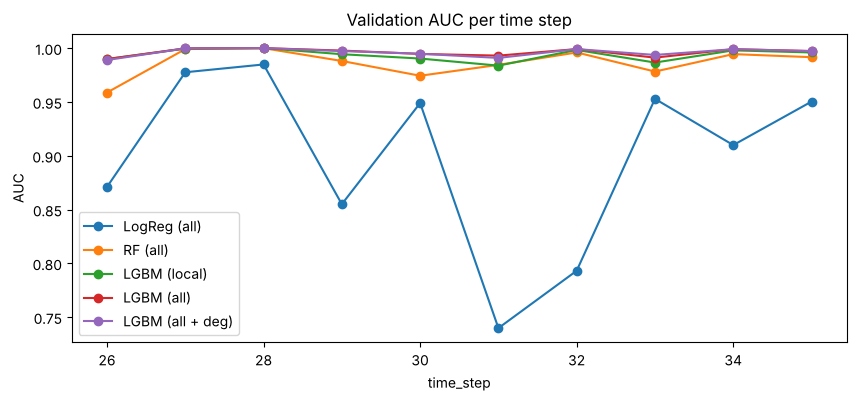

In [6]:
pd.DataFrame(per_step).plot(marker='o', figsize=(10, 4))
plt.title('Validation AUC per time step'); plt.ylabel('AUC'); plt.show()

### Observations
- Trees >> logistic regression. LightGBM is best and fastest.
- Validation AUC (~0.997) is way above the leaderboard top (~0.97). So steps 26–35 are much easier than the test period - expected, since the test covers steps 43+ where the Elliptic data is known to drift (dark market shutdown).
- This means local val can't fully tell us how we'll do on test -> need to use the public LB as a second check, and focus on things that help robustness to drift.

## First submission: LGBM (all feats) trained on all labelled steps 1–35

In [7]:
final_cols = feats
model = make_lgbm()
model.fit(lab[final_cols], lab.y)

sub = pd.DataFrame({'index': test['index'], 'target': model.predict_proba(test[final_cols])[:, 1]})
sub.to_csv('submission_lgbm_baseline.csv', index=False)
sub.describe()

,index,target
count,15329.000000,1.532900e+04
mean,7664.000000,4.107137e-02
std,4425.245473,1.901004e-01
min,0.000000,6.504352e-07
25%,3832.000000,9.455979e-06
50%,7664.000000,3.883788e-05
75%,11496.000000,5.028220e-04
max,15328.000000,9.999503e-01


In [8]:
# sanity: same rows/order as sample submission
ss = pd.read_csv('../data/sample_submission.csv')
assert (ss['index'].values == sub['index'].values).all()
print('ok', sub.shape)

ok (15329, 2)
